# 🫁 Medical Image Classification Network (Chest X-Rays)
### End-to-End Binary Classification Pipeline (Normal vs. Pneumonia)
**Stack:** Python · TensorFlow 2 (Keras) · Scikit-Learn · Matplotlib · Seaborn  
**Dataset:** [Chest X-Ray Images (Pneumonia)](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia)  
**Target Environment:** Google Colab (T4 GPU Accelerator)  

---
### 📑 Table of Contents
1. **Environment & GPU Acceleration** (Seeds, Hardware verification)
2. **Dataset Acquisition via `kagglehub`** (Zero-token direct download)
3. **TensorFlow `tf.data` Pipeline & Augmentation** (Class balance, Batching, Prefetching)
4. **Classical Machine Learning Baseline** (Why CNNs dominate over tabular models)
5. **Custom Deep CNN Architecture** (4 Conv Blocks + BatchNorm + Global Average Pooling)
6. **Loss Function & Training Engine** (Class-weighted Binary Cross-Entropy, Callbacks, Checkpoints)
7. **Clinical Diagnostics via Scikit-Learn** (Confusion Matrix, Sensitivity/Recall, ROC-AUC)
8. **Single-Image Clinical Inference Utility** (Real-time prediction with confidence breakdown)

---
## ⚙️ Section 1 — Environment & Hardware Acceleration

In [1]:
import os
import random
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# ── Core TensorFlow & Keras imports ──────────────────────────────────────────
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers, callbacks, losses

# ── Scikit-Learn for Evaluation & Baselines ──────────────────────────────────
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)
from sklearn.preprocessing import StandardScaler

# ── Set Random Seeds for Deterministic Reproducibility ───────────────────────
# Setting random seeds across Python, NumPy, and TensorFlow guarantees that
# dataset shuffling and weight initialisations yield consistent experimental results.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ── Hardware Verification ────────────────────────────────────────────────────
gpus = tf.config.list_physical_devices('GPU')
print(f"TensorFlow Version : {tf.__version__}")
print(f"GPU Available      : {bool(gpus)}")
if gpus:
    for gpu in gpus:
        print(f"  → Device details : {gpu.name}")
else:
    print("  ⚠️ No GPU detected. In Colab, navigate to: Runtime > Change runtime type > T4 GPU")

TensorFlow Version : 2.21.0
GPU Available      : True
  → Device details : /physical_device:GPU:0


---
## 📂 Section 2 — Dataset Ingestion from Google Drive

We mount **Google Drive** to access the uploaded dataset archive (`chest_xray.zip`) and extract it directly onto the Colab runtime SSD (`/content/`).

This ensures:
1. **Permanent Storage:** The raw dataset persists securely in Google Drive across sessions.
2. **High-Speed GPU I/O:** Extracting to the local runtime SSD allows TensorFlow’s `tf.data` pipeline to stream batches directly to the T4 GPU with zero network latency.

In [2]:
# ==============================================================================
# SECTION 2: Dataset Ingestion from Google Drive (.zip)
# ==============================================================================
import zipfile
from pathlib import Path
from google.colab import drive

# 1. Mount Google Drive
print("🔗 Connecting to Google Drive...")
drive.mount('/content/drive')

# 2. Path to your uploaded zip in Google Drive
# If your zip has a different name, change 'chest_xray.zip' below
ZIP_PATH = Path('/content/drive/MyDrive/chest_xray.zip')

# 3. Extract to fast local runtime SSD (/content/)
print("⚡ Extracting zip to local runtime SSD (takes ~30-45 seconds)...")
with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    zf.extractall('/content')
print("✓ Extraction complete!")

# 4. Set DATA_ROOT
if Path('/content/chest_xray').exists():
    DATA_ROOT = Path('/content/chest_xray')
elif Path('/content/chest-xray-pneumonia/chest_xray').exists():
    DATA_ROOT = Path('/content/chest-xray-pneumonia/chest_xray')
else:
    DATA_ROOT = Path('/content')

TRAIN_DIR = DATA_ROOT / 'train'
VAL_DIR   = DATA_ROOT / 'val'
TEST_DIR  = DATA_ROOT / 'test'

# 5. Verify splits
print(f"\n📂 Working DATA_ROOT: {DATA_ROOT}")
for split, path in [('Train', TRAIN_DIR), ('Val', VAL_DIR), ('Test', TEST_DIR)]:
    print(f"  {split:5s} Split: {'✓ Found' if path.exists() else '✗ Missing'} → {path}")

n_train = len(list((TRAIN_DIR / 'NORMAL').glob('*.*'))) + len(list((TRAIN_DIR / 'PNEUMONIA').glob('*.*')))
print(f"\n Total Training Images Ready: {n_train:,}")
print("✓ Done! Proceed directly to Section 3.")

🔗 Connecting to Google Drive...
Mounted at /content/drive
⚡ Extracting zip to local runtime SSD (takes ~30-45 seconds)...
✓ Extraction complete!

📂 Working DATA_ROOT: /content/chest_xray
  Train Split: ✓ Found → /content/chest_xray/train
  Val   Split: ✓ Found → /content/chest_xray/val
  Test  Split: ✓ Found → /content/chest_xray/test

 Total Training Images Ready: 5,218
✓ Done! Proceed directly to Section 3.


---
## 🔄 Section 3 — TensorFlow Data Pipeline (`tf.data`) & Augmentation

In [3]:
IMG_SIZE   = (224, 224)
BATCH_SIZE = 32
AUTOTUNE   = tf.data.AUTOTUNE

# ── Load datasets using tf.keras.utils.image_dataset_from_directory ──────────
# label_mode='binary' yields 0/1 scalar targets (0: NORMAL, 1: PNEUMONIA)
train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels='inferred',
    label_mode='binary',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED,
)

val_ds_raw = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    labels='inferred',
    label_mode='binary',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

test_ds_raw = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels='inferred',
    label_mode='binary',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

CLASS_NAMES = train_ds_raw.class_names
print(f"\nClass mapping: {CLASS_NAMES} (0 = {CLASS_NAMES[0]}, 1 = {CLASS_NAMES[1]})")

# ── Compute Class Balance & Weights ──────────────────────────────────────────
# Medical datasets often have severe imbalance. Here pneumonia cases outnumber normal.
n_normal = len(list((TRAIN_DIR / 'NORMAL').glob('*.*')))
n_pneumonia = len(list((TRAIN_DIR / 'PNEUMONIA').glob('*.*')))
n_total = n_normal + n_pneumonia

# Weight per class = (1 / ClassCount) * (Total / 2.0)
# This ensures balanced gradients during gradient descent
weight_for_0 = (1 / n_normal) * (n_total / 2.0)
weight_for_1 = (1 / n_pneumonia) * (n_total / 2.0)
CLASS_WEIGHTS = {0: weight_for_0, 1: weight_for_1}

print(f"\nClass distribution:")
print(f"  NORMAL    : {n_normal:,} ({n_normal/n_total*100:.1f}%) → Class Weight: {weight_for_0:.2f}")
print(f"  PNEUMONIA : {n_pneumonia:,} ({n_pneumonia/n_total*100:.1f}%) → Class Weight: {weight_for_1:.2f}")

# ── Data Augmentation Pipeline as Keras Layers ───────────────────────────────
# Integrating augmentation layers directly inside the model/pipeline ensures
# GPU acceleration and ensures augmentations are strictly disabled during evaluation!
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.03, seed=SEED), # ~10 degrees rotation
    layers.RandomContrast(0.1, seed=SEED),
], name="data_augmentation")

# ── Optimize tf.data execution pipeline ──────────────────────────────────────
# cache() keeps images in memory after first epoch; prefetch() prepares batches
# on CPU in parallel while GPU is running backward pass.
train_ds = train_ds_raw.cache().shuffle(1000, seed=SEED).prefetch(buffer_size=AUTOTUNE)
val_ds   = val_ds_raw.cache().prefetch(buffer_size=AUTOTUNE)
test_ds  = test_ds_raw.cache().prefetch(buffer_size=AUTOTUNE)

print("✓ tf.data caching and prefetching configured.")

Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.

Class mapping: ['NORMAL', 'PNEUMONIA'] (0 = NORMAL, 1 = PNEUMONIA)

Class distribution:
  NORMAL    : 1,342 (25.7%) → Class Weight: 1.94
  PNEUMONIA : 3,876 (74.3%) → Class Weight: 0.67
✓ tf.data caching and prefetching configured.


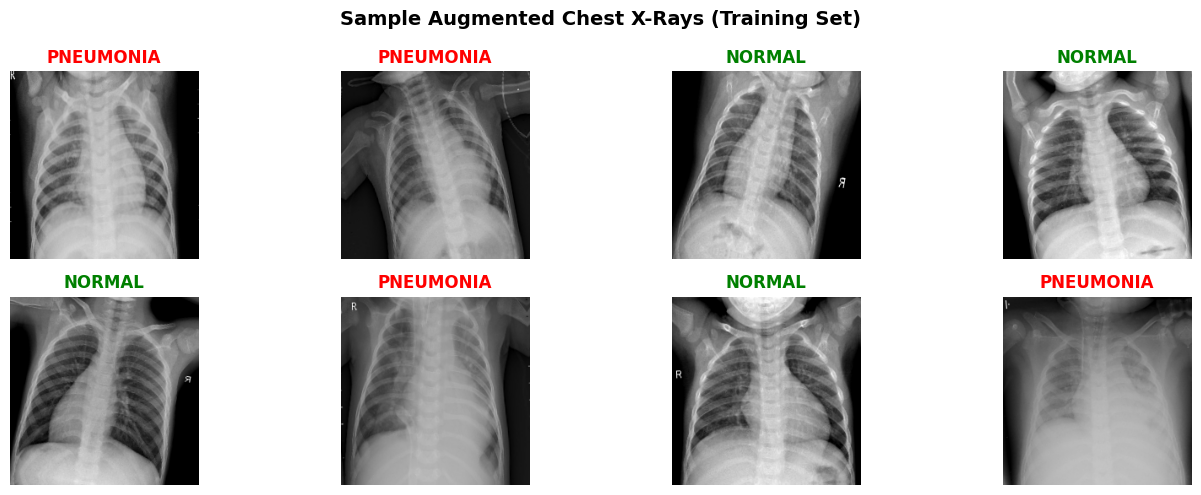

In [5]:
# Visualise a sample batch with augmentation applied
for images, labels in train_ds_raw.take(1):
    plt.figure(figsize=(14, 5))
    for i in range(8):
        ax = plt.subplot(2, 4, i + 1)
        augmented_img = data_augmentation(images[i:i+1], training=True)[0]
        plt.imshow(augmented_img.numpy().astype("uint8"))
        cls_name = CLASS_NAMES[int(labels[i].numpy()[0])]
        plt.title(f"{cls_name}", color="red" if cls_name == "PNEUMONIA" else "green", fontweight="bold")
        plt.axis("off")
    plt.suptitle("Sample Augmented Chest X-Rays (Training Set)", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

---
## 📊 Section 4 — Scikit-Learn Baseline Comparison (Proof of Concept)

> **Why this is critical for interview discussions:**  
> Flattening an image into a 1D vector completely ignores 2D spatial locality. Linear models and Decision Forests cannot exploit translational invariance or hierarchical spatial filters (edges → textures → opacities). We prove this quantitatively below.

In [6]:
print("Extracting sample 32x32 flattened vectors for Scikit-Learn baseline...")

def extract_flattened_subset(dataset, max_samples=600):
    X_list, y_list = [], []
    count = 0
    for imgs, lbls in dataset:
        # Downsample to 32x32 to prevent tabular dimensionality explosion (32*32*3 = 3072)
        resized = tf.image.resize(imgs, (32, 32))
        flattened = tf.reshape(resized, [imgs.shape[0], -1]).numpy()
        X_list.append(flattened)
        y_list.append(lbls.numpy().ravel())
        count += imgs.shape[0]
        if count >= max_samples:
            break
    return np.concatenate(X_list)[:max_samples], np.concatenate(y_list)[:max_samples]

X_train_base, y_train_base = extract_flattened_subset(train_ds_raw, max_samples=800)
X_test_base,  y_test_base  = extract_flattened_subset(test_ds_raw,  max_samples=400)

# Scale pixel values for Logistic Regression stability
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_base)
X_test_scaled  = scaler.transform(X_test_base)

# Train Logistic Regression
lr_clf = LogisticRegression(max_iter=500, solver='lbfgs', random_state=SEED)
lr_clf.fit(X_train_scaled, y_train_base)
lr_preds = lr_clf.predict(X_test_scaled)
lr_acc = accuracy_score(y_test_base, lr_preds)

# Train Random Forest
rf_clf = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)
rf_clf.fit(X_train_base, y_train_base)
rf_preds = rf_clf.predict(X_test_base)
rf_acc = accuracy_score(y_test_base, rf_preds)

print(f"\n── Baseline Classical Machine Learning Results ──")
print(f"  Logistic Regression Accuracy : {lr_acc * 100:.2f}%")
print(f"  Random Forest Accuracy       : {rf_acc * 100:.2f}%")
print("\n💡 Insight: Tabular models fail to capture lung opacities, focal consolidations,")
print("   and anatomical margins because they treat adjacent pixels as independent features.")

Extracting sample 32x32 flattened vectors for Scikit-Learn baseline...

── Baseline Classical Machine Learning Results ──
  Logistic Regression Accuracy : 63.75%
  Random Forest Accuracy       : 58.00%

💡 Insight: Tabular models fail to capture lung opacities, focal consolidations,
   and anatomical margins because they treat adjacent pixels as independent features.


---
## 🧠 Section 5 — Custom Deep CNN Architecture in TensorFlow / Keras

### Architectural Topology:
```
Input (224, 224, 3)
  │
  ├── Rescaling(1./255)  [Normalizes pixel values [0, 255] -> [0.0, 1.0]]
  ├── Data Augmentation  [Flip, Subtle Rotation, Contrast]
  │
  ├── ConvBlock 1: Conv2D(32, 3x3)  → BatchNorm → ReLU → MaxPool2D(2x2)
  ├── ConvBlock 2: Conv2D(64, 3x3)  → BatchNorm → ReLU → MaxPool2D(2x2)
  ├── ConvBlock 3: Conv2D(128, 3x3) → BatchNorm → ReLU → MaxPool2D(2x2)
  ├── ConvBlock 4: Conv2D(256, 3x3) → BatchNorm → ReLU → MaxPool2D(2x2)
  │
  ├── GlobalAveragePooling2D [Drastically reduces parameter count]
  ├── Dense(128, activation='relu')
  ├── Dropout(0.4) [Mitigates co-adaptation & overfitting]
  └── Dense(1, activation=None) [Outputs raw scalar logit per image]
```

In [7]:
def build_medical_cnn(input_shape=(224, 224, 3)) -> keras.Model:
    """
    Builds a custom 4-block deep convolutional neural network for binary medical image diagnosis.
    """
    inputs = layers.Input(shape=input_shape, name="input_image")

    # 1. Preprocessing & Normalization inside model graph
    x = layers.Rescaling(1.0 / 255.0, name="rescaling")(inputs)
    x = data_augmentation(x)

    # 2. Convolutional Feature Extractor
    filters = [32, 64, 128, 256]
    for i, f in enumerate(filters, start=1):
        x = layers.Conv2D(f, kernel_size=(3, 3), padding="same", use_bias=False, name=f"conv_{i}")(x)
        x = layers.BatchNormalization(name=f"bn_{i}")(x)
        x = layers.ReLU(name=f"relu_{i}")(x)
        x = layers.MaxPooling2D(pool_size=(2, 2), name=f"maxpool_{i}")(x)

    # 3. Global Average Pooling (decouples feature maps from dense layer dimensionality)
    x = layers.GlobalAveragePooling2D(name="global_avg_pool")(x)

    # 4. Dense Diagnostic Classifier Head
    x = layers.Dense(128, activation="relu", name="dense_128")(x)
    x = layers.Dropout(0.4, name="dropout_40")(x)

    # Output 1 raw logit (from_logits=True ensures numerical stability in BCE loss)
    outputs = layers.Dense(1, activation=None, name="logits")(x)

    model = keras.Model(inputs=inputs, outputs=outputs, name="MedicalXRayCNN")
    return model

model = build_medical_cnn()
model.summary()

# Verification dry run on dummy batch
dummy_tensor = tf.random.normal([1, 224, 224, 3])
out_dummy = model(dummy_tensor, training=False)
print(f"\n✓ Model forward pass verified. Output logit shape: {out_dummy.shape}")

Model: "MedicalXRayCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (ReLU)                   │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_1 (MaxPooling2D)        │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_2 (BatchNormalization)       │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2 (ReLU)                   │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_2 (MaxPooling2D)        │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_3 (BatchNormalization)       │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_3 (ReLU)                   │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_3 (MaxPooling2D)        │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_4 (Conv2D)                 │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_4 (BatchNormalization)       │ (None, 28, 28, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_4 (ReLU)                   │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_4 (MaxPooling2D)        │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_40 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 422,881 (1.61 MB)

 Trainable params: 421,921 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)


✓ Model forward pass verified. Output logit shape: (1, 1)


---
## 🏋️ Section 6 — Loss Function, Optimizer & Training Engine

In [8]:
# ── Compile Model ────────────────────────────────────────────────────────────
# BinaryCrossentropy(from_logits=True) mathematically couples sigmoid + log loss
# into a single numerically stable formula avoiding overflow/underflow.
model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-4),
    loss=losses.BinaryCrossentropy(from_logits=True),
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy", threshold=0.0),
        keras.metrics.AUC(from_logits=True, name="auc"),
    ],
)

# ── Training Callbacks ───────────────────────────────────────────────────────
checkpoint_cb = callbacks.ModelCheckpoint(
    filepath="best_medical_cnn.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1,
)

reduce_lr_cb = callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1,
)

early_stopping_cb = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1,
)

# ── Model Training Loop ─────────────────────────────────────────────────────
EPOCHS = 20
print(f"Starting training for {EPOCHS} epochs with class weighting...")

start_time = time.time()
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=CLASS_WEIGHTS,
    callbacks=[checkpoint_cb, reduce_lr_cb, early_stopping_cb],
)
training_time = time.time() - start_time
print(f"\n✓ Training finished in {training_time / 60:.1f} minutes.")

Starting training for 20 epochs with class weighting...
Epoch 1/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.8050 - auc: 0.8754 - loss: 0.4216
Epoch 1: val_loss improved from None to 3.06101, saving model to best_medical_cnn.keras

Epoch 1: finished saving model to best_medical_cnn.keras
163/163 ━━━━━━━━━━━━━━━━━━━━ 64s 125ms/step - accuracy: 0.8470 - auc: 0.9280 - loss: 0.3361 - val_accuracy: 0.5000 - val_auc: 0.5000 - val_loss: 3.0610 - learning_rate: 1.0000e-04
Epoch 2/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step - accuracy: 0.9103 - auc: 0.9655 - loss: 0.2264
Epoch 2: val_loss did not improve from 3.06101
163/163 ━━━━━━━━━━━━━━━━━━━━ 20s 123ms/step - accuracy: 0.9045 - auc: 0.9663 - loss: 0.2269 - val_accuracy: 0.5000 - val_auc: 0.5000 - val_loss: 3.6726 - learning_rate: 1.0000e-04
Epoch 3/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step - accuracy: 0.9213 - auc: 0.9725 - loss: 0.2038
Epoch 3: val_loss improved from 3.06101 to 2.04611, saving model to best_medical_cnn.

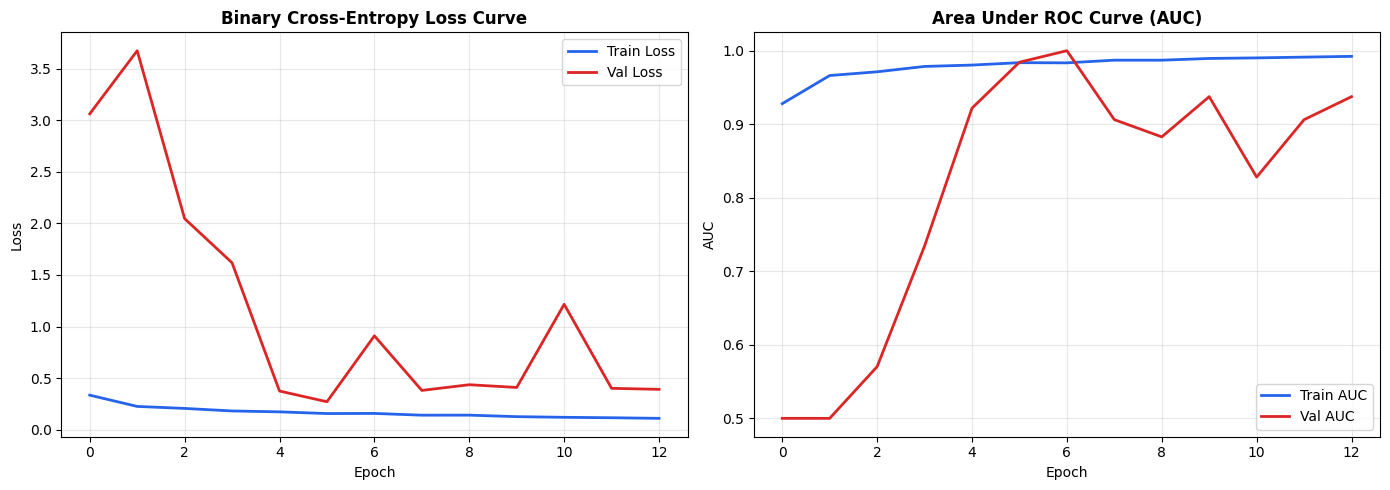

In [9]:
# Plot Training & Validation Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss
axes[0].plot(history.history['loss'], label='Train Loss', color='#2563EB', lw=2)
axes[0].plot(history.history['val_loss'], label='Val Loss', color='#DC2626', lw=2)
axes[0].set_title('Binary Cross-Entropy Loss Curve', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

# AUC
axes[1].plot(history.history['auc'], label='Train AUC', color='#2563EB', lw=2)
axes[1].plot(history.history['val_auc'], label='Val AUC', color='#DC2626', lw=2)
axes[1].set_title('Area Under ROC Curve (AUC)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('AUC')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("training_curves_tf.png", dpi=150)
plt.show()

---
## 🏥 Section 7 — Clinical Diagnostics & Evaluation via Scikit-Learn

We evaluate the best checkpoint on the unseen `test` partition across clinical diagnostic criteria.

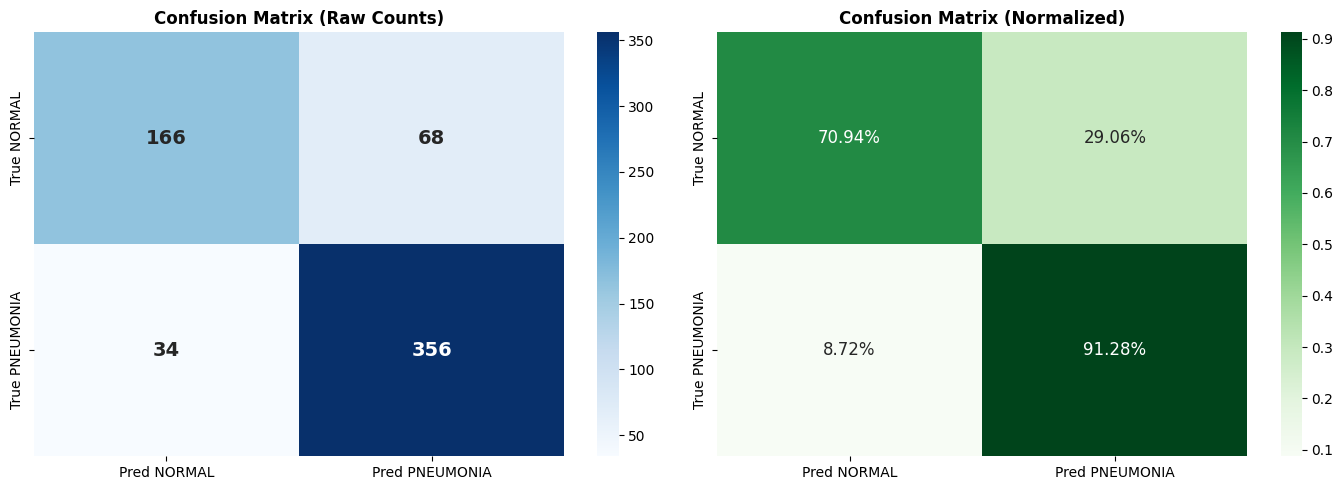

           MEDICAL DIAGNOSTIC PERFORMANCE REPORT
  True Positives  (TP) : 356  |  False Positives (FP) :  68
  True Negatives  (TN) : 166  |  False Negatives (FN) :  34
-----------------------------------------------------------------
  Sensitivity (Recall) : 91.28%  (CRITICAL: Minimizes missed sick patients)
  Specificity          : 70.94%
  Precision (PPV)      : 83.96%
  Overall Accuracy     : 83.65%

Full Scikit-Learn Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.83      0.71      0.76       234
   PNEUMONIA       0.84      0.91      0.87       390

    accuracy                           0.84       624
   macro avg       0.83      0.81      0.82       624
weighted avg       0.84      0.84      0.83       624



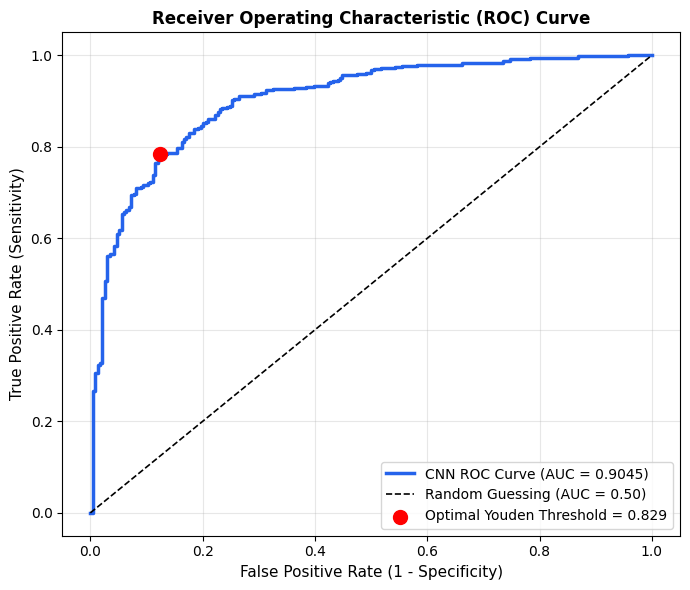

✓ Test ROC-AUC Score: 0.9045


In [10]:
# ── Load Best Weights & Generate Predictions on Held-Out Test Set ─────────────
best_model = keras.models.load_model("best_medical_cnn.keras")

y_true = []
y_logits = []

for images, labels in test_ds:
    logits = best_model(images, training=False).numpy().ravel()
    y_logits.extend(logits)
    y_true.extend(labels.numpy().ravel())

y_true = np.array(y_true)
y_logits = np.array(y_logits)
# Apply sigmoid to map raw logits to probability P(Pneumonia)
y_probs = tf.sigmoid(y_logits).numpy()
y_preds = (y_probs >= 0.5).astype(int)

# ── Confusion Matrix ──────────────────────────────────────────────────────────
cm = confusion_matrix(y_true, y_preds)
tn, fp, fn, tp = cm.ravel()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
    xticklabels=['Pred NORMAL', 'Pred PNEUMONIA'],
    yticklabels=['True NORMAL', 'True PNEUMONIA'],
    annot_kws={'size': 14, 'weight': 'bold'}
)
axes[0].set_title('Confusion Matrix (Raw Counts)', fontsize=12, fontweight='bold')

cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(
    cm_norm, annot=True, fmt='.2%', cmap='Greens', ax=axes[1],
    xticklabels=['Pred NORMAL', 'Pred PNEUMONIA'],
    yticklabels=['True NORMAL', 'True PNEUMONIA'],
    annot_kws={'size': 12}
)
axes[1].set_title('Confusion Matrix (Normalized)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# ── Clinical Metrics Calculation ─────────────────────────────────────────────
sensitivity = tp / (tp + fn)  # Recall for Pneumonia
specificity = tn / (tn + fp)  # True negative rate
ppv = tp / (tp + fp)          # Positive predictive value
npv = tn / (tn + fn)          # Negative predictive value

print("=" * 65)
print("           MEDICAL DIAGNOSTIC PERFORMANCE REPORT")
print("=" * 65)
print(f"  True Positives  (TP) : {tp:3d}  |  False Positives (FP) : {fp:3d}")
print(f"  True Negatives  (TN) : {tn:3d}  |  False Negatives (FN) : {fn:3d}")
print("-" * 65)
print(f"  Sensitivity (Recall) : {sensitivity * 100:.2f}%  (CRITICAL: Minimizes missed sick patients)")
print(f"  Specificity          : {specificity * 100:.2f}%")
print(f"  Precision (PPV)      : {ppv * 100:.2f}%")
print(f"  Overall Accuracy     : {accuracy_score(y_true, y_preds) * 100:.2f}%")
print("=" * 65)
print("\nFull Scikit-Learn Classification Report:")
print(classification_report(y_true, y_preds, target_names=CLASS_NAMES))

# ── ROC Curve & Area Under the Curve (AUC) ───────────────────────────────────
fpr, tpr, thresholds = roc_curve(y_true, y_probs)
test_auc = roc_auc_score(y_true, y_probs)

# Youden's J statistic maximizes (Sensitivity + Specificity - 1)
youden_idx = np.argmax(tpr - fpr)
best_thresh = thresholds[youden_idx]

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='#2563EB', lw=2.5, label=f'CNN ROC Curve (AUC = {test_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1.2, label='Random Guessing (AUC = 0.50)')
plt.scatter(fpr[youden_idx], tpr[youden_idx], color='red', s=100, zorder=5,
            label=f'Optimal Youden Threshold = {best_thresh:.3f}')
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=11)
plt.title('Receiver Operating Characteristic (ROC) Curve', fontsize=12, fontweight='bold')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("roc_curve_tf.png", dpi=150)
plt.show()
print(f"✓ Test ROC-AUC Score: {test_auc:.4f}")

---
## 🔍 Section 8 — Single-Image Clinical Inference Utility

A standalone utility for clinical deployment: takes a single local chest X-ray file, preprocesses it, performs the forward pass, and plots the visual diagnosis.


--- Demonstrating Prediction on Sample NORMAL X-Ray ---


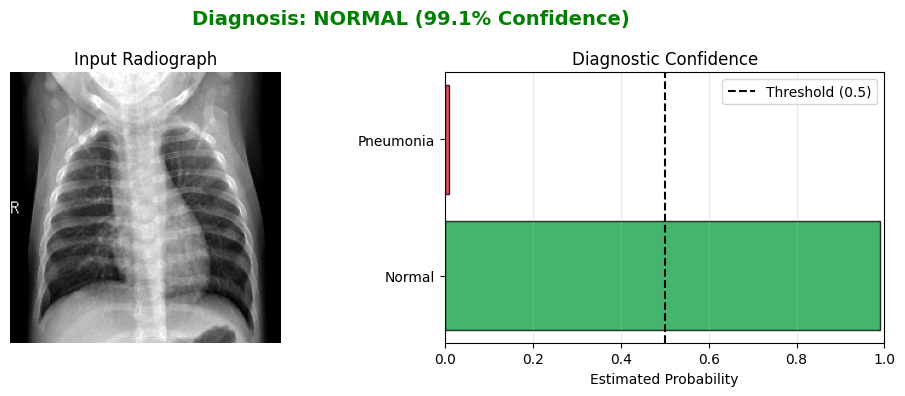


--- Demonstrating Prediction on Sample PNEUMONIA X-Ray ---


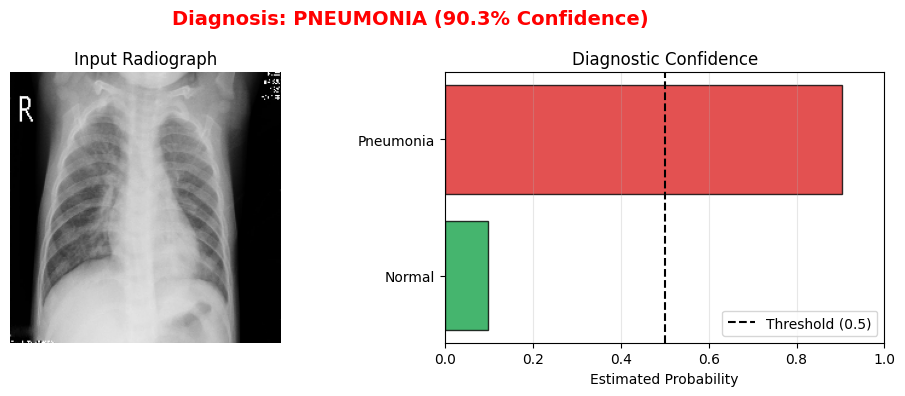

In [11]:
def predict_single_xray(image_path: str, model: keras.Model, threshold: float = 0.5) -> dict:
    """
    Runs inference on a single image file and displays clinical confidence.
    """
    # Load and resize image via PIL & Keras utils
    img = keras.utils.load_img(image_path, target_size=(224, 224))
    img_array = keras.utils.img_to_array(img)
    input_tensor = np.expand_dims(img_array, axis=0)  # Shape: (1, 224, 224, 3)

    # Forward pass (eval mode)
    logit = model.predict(input_tensor, verbose=0)[0][0]
    probability = tf.sigmoid(logit).numpy()

    diagnosis = "PNEUMONIA" if probability >= threshold else "NORMAL"
    confidence = probability if diagnosis == "PNEUMONIA" else (1.0 - probability)

    # Plot visual outcome
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(img)
    axes[0].axis('off')
    axes[0].set_title("Input Radiograph", fontsize=12)

    bars = axes[1].barh(["Normal", "Pneumonia"], [1.0 - probability, probability],
                        color=['#16A34A', '#DC2626'], edgecolor='black', alpha=0.8)
    axes[1].set_xlim([0, 1])
    axes[1].set_xlabel("Estimated Probability")
    axes[1].axvline(threshold, color='black', linestyle='--', label=f'Threshold ({threshold})')
    axes[1].legend()
    axes[1].set_title("Diagnostic Confidence", fontsize=12)
    axes[1].grid(axis='x', alpha=0.3)

    title_color = "red" if diagnosis == "PNEUMONIA" else "green"
    plt.suptitle(f"Diagnosis: {diagnosis} ({confidence*100:.1f}% Confidence)",
                 fontsize=14, fontweight='bold', color=title_color)
    plt.tight_layout()
    plt.show()

    return {
        "image_path": image_path,
        "diagnosis": diagnosis,
        "confidence": float(confidence),
        "pneumonia_probability": float(probability),
        "raw_logit": float(logit)
    }

# Run test demonstrations on both classes
test_normal_samples = list((TEST_DIR / 'NORMAL').glob('*.*'))
test_pneum_samples  = list((TEST_DIR / 'PNEUMONIA').glob('*.*'))

if test_normal_samples:
    print("\n--- Demonstrating Prediction on Sample NORMAL X-Ray ---")
    predict_single_xray(str(test_normal_samples[0]), best_model)

if test_pneum_samples:
    print("\n--- Demonstrating Prediction on Sample PNEUMONIA X-Ray ---")
    predict_single_xray(str(test_pneum_samples[0]), best_model)

In [12]:
# 1. Mount Google Drive (run after training finishes)
from google.colab import drive
drive.mount('/content/drive')

# 2. Copy the trained model to your Drive
!cp best_medical_cnn.keras /content/drive/MyDrive/best_medical_cnn.keras
print("✓ Model saved permanently to Google Drive!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✓ Model saved permanently to Google Drive!
